<a href="https://colab.research.google.com/github/Zard3017/CreditScoring_system/blob/main/notebooks/credit_scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project setup

In [51]:
# Confirm where the Python interpreter is located
import sys
print(sys.executable)
# print(sys.version)

/usr/bin/python3


In [52]:
# Confirm the version of the Python interpreter
!{sys.executable} --version

Python 3.13.16


In [53]:
import os
from dotenv import load_dotenv

# This loads .env from the current (or parent) directory if present
# `override=True` ensures that the values set in the .env file take precedence
# over any existing environment variables set in the Operating System
load_dotenv(override=True)

def resolve_environment():
    if os.environ.get("ENVIRONMENT"):
        return os.environ["ENVIRONMENT"].upper()

    # Automatic detection if running in Google Colab
    if "google.colab" in sys.modules:
        return "COLAB"

    # Defaults to a 'DEV' environment if it is not set
    return "DEV"

ENV_SETUP = resolve_environment()

VALID_ENVIRONMENTS = {"PROD", "STAGING", "TESTING", "COLAB", "DEV"}

if ENV_SETUP not in VALID_ENVIRONMENTS:
    print(f"Warning: Invalid ENVIRONMENT '{ENV_SETUP}'. Defaulting to 'DEV'.")
    ENV_SETUP = "DEV"

print(f"Dependencies will be installed for a '{ENV_SETUP}' environment.")

Dependencies will be installed for a 'COLAB' environment.


In [54]:
import sys
import subprocess

def silent_pip_install(args):
    """
    Used to run a command quietly and
    only shows an error if something went wrong.
    :param args: Array of arguments that form the command.
    :return:
    """

    # `sys.executable` is added to ensure you are installing into the virtual environment
    cmd = [sys.executable, "-m", "pip", *args]
    # `subprocess.run` is used to execute an external command
    # `stdout=subprocess.PIPE` captures normal output into result.stdout
    # `stderr=subprocess.PIPE` captures error output into result.stderr
    # `text=True` decodes output as strings (str) instead of bytes, so you can print/read it directly.
    result = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True)
    # `result.returncode` is the process exit status. 0 means success.
    if result.returncode != 0:
        print(result.stderr)

if ENV_SETUP == "PROD":
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/prod.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"STAGING"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"TESTING"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"COLAB"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/colab.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

elif ENV_SETUP in {"DEV"}:
    silent_pip_install([
        "install", "-r",
        "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/dev.txt",
        "-c", "https://raw.githubusercontent.com/course-files/RegressionAndClassification/refs/heads/main/requirements/constraints.txt"
    ])
    print(f"Completed installation of environment dependencies for '{ENV_SETUP}'.")

Completed installation of environment dependencies for 'COLAB'.


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# For suppressing warnings displayed in the notebook
import warnings
warnings.filterwarnings('ignore')

print("The environment is ready.")

The environment is ready.


# Load Data

In [56]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [57]:
import os

# Replace this path with the copied path of your CSV from your Google Drive
# Usually it starts with '/content/drive/MyDrive/...'
file_path = "/content/drive/MyDrive/Credit_Dataset/kenya_msme_credit_scoring_5000.csv"

if os.path.exists(file_path):
    sme_data = pd.read_csv(file_path)
    print(f"Data loaded successfully from Drive! Shape: {sme_data.shape}")
    display(sme_data.head(20))
else:
    print(f"File not found at '{file_path}'. Please check the folder path in your Google Drive and update the file_path variable above.")

Data loaded successfully from Drive! Shape: (5021, 19)


,business_id,sector,business_age_years,legal_status,location_type,employees_count,existing_loans,prior_loan_count,late_payment_history,collateral_level,cashflow_stability,missed_payment_last_12m,repayment_confidence,owner_education,days_payable_outstanding,target_missed_payment,monthly_revenue_kes,monthly_profit_kes,county
0,SME0001,Manufacturing,15,Limited,Urban,23,Yes,0,Rarely,Low,5,No,4,Primary,45,0,427297.0,102296.0,Nairobi
1,SME0002,Retail,16,Sole,Urban,13,Yes,2,Never,High,3,No,2,Secondary,30,0,1655861.0,453751.0,Narok
2,SME0003,Retail,17,Sole,Urban,7,Yes,2,Never,Low,4,Yes,4,Master's,75,1,694837.0,185940.0,Machakos
3,SME0004,Agriculture,13,Sole,Rural,8,Yes,0,Never,High,4,No,5,Higher Secondary,90,0,822519.0,183149.0,Kiambu
4,SME0005,Agriculture,1,Sole,Rural,6,Yes,1,Never,Moderate,3,No,4,Secondary,40,0,1082078.0,346752.0,Uasin Gishu
5,SME0006,Retail,19,Sole,Rural,22,Yes,3,Never,Low,2,Yes,4,Secondary,30,1,1666017.0,548043.0,Uasin Gishu
6,SME0007,Retail,19,Sole,Urban,10,Yes,0,Rarely,Low,5,No,4,Secondary,60,0,1309476.0,179230.0,Nairobi
7,SME0008,Manufacturing,6,Sole,Urban,21,Yes,2,Never,Low,1,Yes,4,Primary,30,1,2792701.0,602172.0,Kisii
8,SME0009,Retail,1,Sole,Urban,12,No,3,Never,Moderate,3,Yes,2,Master's,40,1,1112529.0,166326.0,Kericho
9,SME0010,Services,3,Limited,Urban,21,No,2,Never,Low,4,No,4,Primary,90,0,306397.0,49643.0,Bungoma


In [58]:
sme_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5021 entries, 0 to 5020
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   business_id               5021 non-null   object 
 1   sector                    5021 non-null   object 
 2   business_age_years        5021 non-null   int64  
 3   legal_status              5021 non-null   object 
 4   location_type             5021 non-null   object 
 5   employees_count           5021 non-null   int64  
 6   existing_loans            5021 non-null   object 
 7   prior_loan_count          5021 non-null   int64  
 8   late_payment_history      5021 non-null   object 
 9   collateral_level          5021 non-null   object 
 10  cashflow_stability        5021 non-null   int64  
 11  missed_payment_last_12m   5021 non-null   object 
 12  repayment_confidence      5021 non-null   int64  
 13  owner_education           5021 non-null   object 
 14  days_pay

# Identifying the Target variable

### Chosen Target: `target_missed_payment`

For this project, the target variable is **`target_missed_payment`**, a binary
indicator representing whether an MSME is expected to miss a payment.

### Features Excluded from the Model (Leakage Prevention)

- `business_id` — Unique identifier, not a predictive feature
- `missed_payment_last_12m` — Semantically equivalent to the target, so it
  is dropped to prevent target leakage

In [59]:
TARGET = "target_missed_payment"

# business_id is an identifier, not a predictive feature
# missed_payment_last_12m is dropped to prevent target leakage
DROP_COLS = ["business_id", "missed_payment_last_12m", TARGET]

print(f"Target variable: {TARGET}")
print(f"Problem type: Binary Classification")
print(f"Number of features: {sme_data.shape[1] - len(DROP_COLS)}")

Target variable: target_missed_payment
Problem type: Binary Classification
Number of features: 16


# Initial Exploratory Data Analysis

## Descriptive Analysis

This section profiles the dataset by identifying numeric and categorical
columns, and computing a comprehensive set of descriptive statistics for
each numeric feature. The goal is to understand central tendency, spread,
shape (skewness / kurtosis), and detect potential outliers using the
1.5 × IQR rule before modelling.

In [60]:


# Identify numeric and categorical columns
numeric_cols = sme_data.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop("business_id", errors="ignore")

categorical_cols = sme_data.select_dtypes(exclude=[np.number, "datetime64[ns]"]).columns
categorical_cols = categorical_cols.drop("business_id", errors="ignore")

print("The identified numeric columns (measures) are:")
print(numeric_cols.tolist())

print("\nThe identified categorical columns (dimensions) are:")
print(categorical_cols.tolist())

The identified numeric columns (measures) are:
['business_age_years', 'employees_count', 'prior_loan_count', 'cashflow_stability', 'repayment_confidence', 'days_payable_outstanding', 'target_missed_payment', 'monthly_revenue_kes', 'monthly_profit_kes']

The identified categorical columns (dimensions) are:
['sector', 'legal_status', 'location_type', 'existing_loans', 'late_payment_history', 'collateral_level', 'missed_payment_last_12m', 'owner_education', 'county']


##Quartiles and Interquatiles

In [61]:
# Quartiles
q1 = sme_data[numeric_cols].quantile(0.25)
q2 = sme_data[numeric_cols].quantile(0.50)
q3 = sme_data[numeric_cols].quantile(0.75)

# Interquartile Range
iqr = q3 - q1

print("Quartiles and IQR computed ")
print(f"Number of numeric features: {len(numeric_cols)}")

Quartiles and IQR computed 
Number of numeric features: 9


In [62]:
distribution_summary = pd.DataFrame({
    "min":          sme_data[numeric_cols].min(),
    "q1_25%":       q1,
    "q2_50%":       q2,
    "q3_75%":       q3,
    "max":          sme_data[numeric_cols].max(),
    "mean":         sme_data[numeric_cols].mean(),
    "mode":         sme_data[numeric_cols].mode().iloc[0],
    "variance":     sme_data[numeric_cols].var(),
    "std_dev":      sme_data[numeric_cols].std(),
    "skewness":     sme_data[numeric_cols].skew(),
    "kurtosis":     sme_data[numeric_cols].kurt(),
    "IQR":          iqr,
    "lower_fence":  q1 - 1.5 * iqr,
    "upper_fence":  q3 + 1.5 * iqr,
})

distribution_summary.round(2).style.format("{:,.2f}")

,min,q1_25%,q2_50%,q3_75%,max,mean,mode,variance,std_dev,skewness,kurtosis,IQR,lower_fence,upper_fence
business_age_years,1.00,5.00,9.00,13.00,25.00,9.11,1.00,24.78,4.98,0.21,-0.65,8.00,-7.00,25.00
employees_count,2.00,8.00,14.00,21.00,50.00,15.22,2.00,91.04,9.54,0.73,0.43,13.00,-11.50,40.50
prior_loan_count,0.00,0.00,1.00,2.00,3.00,1.18,0.00,1.08,1.04,0.39,-1.04,2.00,-3.00,5.00
cashflow_stability,1.00,2.00,3.00,4.00,5.00,3.01,3.00,1.11,1.05,-0.05,-0.57,2.00,-1.00,7.00
repayment_confidence,1.00,2.00,3.00,4.00,5.00,2.80,3.00,1.67,1.29,0.09,-1.10,2.00,-1.00,7.00
days_payable_outstanding,5.00,26.00,43.00,60.00,120.00,44.19,5.00,577.68,24.03,0.28,-0.62,34.00,-25.00,111.00
target_missed_payment,0.00,0.00,0.00,1.00,1.00,0.29,0.00,0.21,0.46,0.91,-1.17,1.00,-1.50,2.50
monthly_revenue_kes,"32,754.00","296,521.00","569,719.00","1,005,836.00","3,781,078.00","784,488.95","165,271.00","514,148,435,615.67","717,041.45",1.69,2.81,"709,315.00","-767,451.50","2,069,808.50"
monthly_profit_kes,"5,510.00","72,977.00","149,485.00","266,654.00","1,417,647.00","204,404.24","8,263.00","37,133,974,862.16","192,701.78",1.99,5.03,"193,677.00","-217,538.50","557,169.50"


The target variable `target_missed_payment` has a skewness of **0.91**,
indicating a **moderately right-skewed distribution**

In [63]:
# Count how many rows fall outside the IQR fences (potential outliers)
outlier_counts = {}

for col in numeric_cols:
    lower = distribution_summary.loc[col, "lower_fence"]
    upper = distribution_summary.loc[col, "upper_fence"]
    n_out = ((sme_data[col] < lower) | (sme_data[col] > upper)).sum()
    outlier_counts[col] = n_out

outliers_df = pd.DataFrame({
    "outlier_count": pd.Series(outlier_counts),
    "outlier_pct":   (pd.Series(outlier_counts) / len(sme_data) * 100).round(2)
}).sort_values("outlier_count", ascending=False)

print("Potential outliers per numeric feature (1.5 × IQR rule):")
outliers_df

Potential outliers per numeric feature (1.5 × IQR rule):


,outlier_count,outlier_pct
monthly_revenue_kes,382,7.61
monthly_profit_kes,310,6.17
employees_count,88,1.75
days_payable_outstanding,11,0.22
business_age_years,0,0.00
repayment_confidence,0,0.00
cashflow_stability,0,0.00
prior_loan_count,0,0.00
target_missed_payment,0,0.00


## Measures of Relationship

### Spearman's Correlation

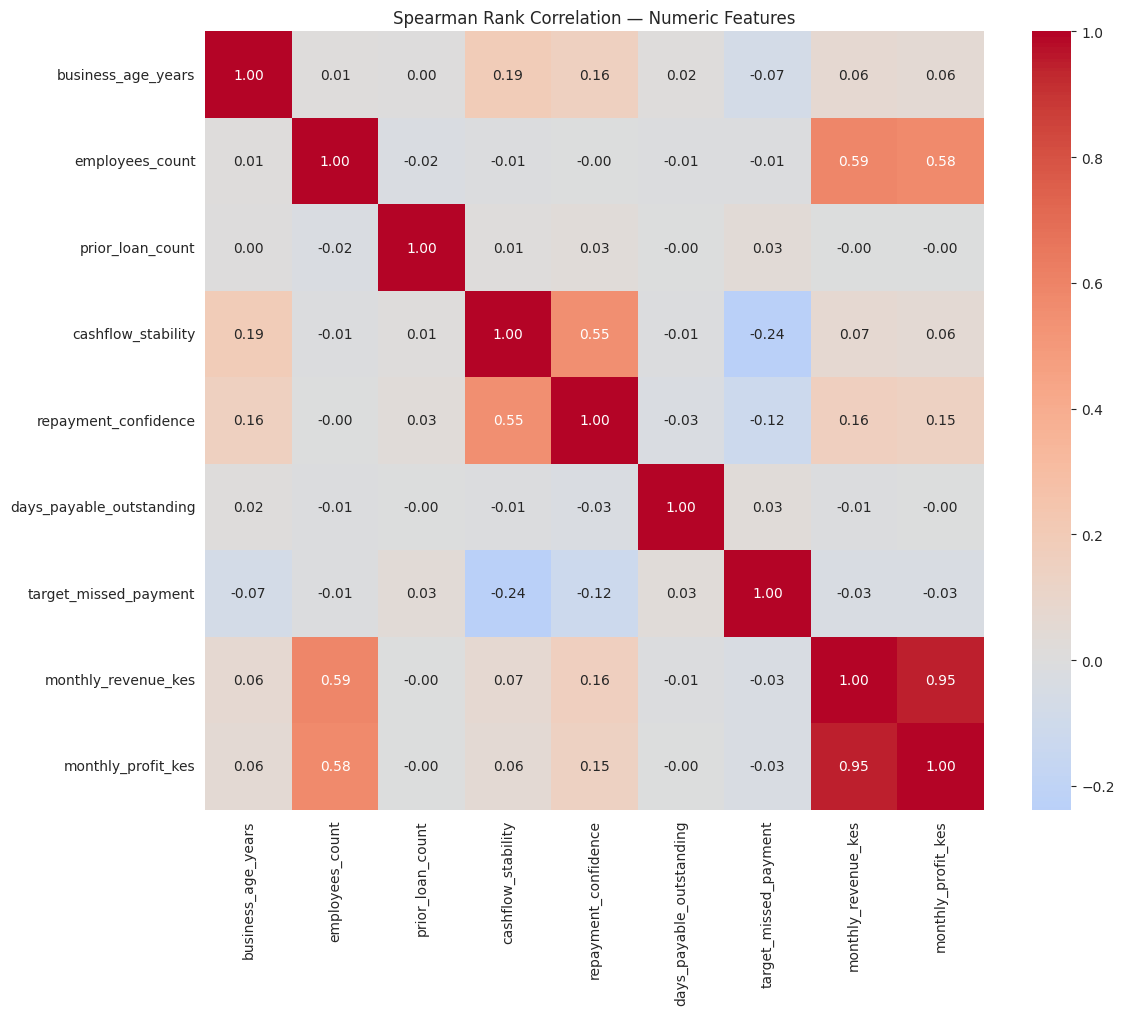

In [64]:
# Spearman correlation (robust)
spearman_corr = sme_data[numeric_cols].corr(method='spearman')

plt.figure(figsize=(12, 10))
sns.heatmap(spearman_corr, annot=True, fmt=".2f",
            cmap='coolwarm', center=0, square=True)
plt.title("Spearman Rank Correlation — Numeric Features")
plt.tight_layout()
plt.show()

### Point Biserial Correlation

Point-biserial correlation is used to measure the linear association
between each numeric feature and the binary target variable
(`target_missed_payment`).

In [65]:
from scipy.stats import pointbiserialr

pb_results = {}
for col in numeric_cols:
    if col == 'target_missed_payment':
        continue
    r, p = pointbiserialr(sme_data[col], sme_data['target_missed_payment'])
    pb_results[col] = {'r': round(r, 3), 'p_value': round(p, 4)}

pb_df = pd.DataFrame(pb_results).T.sort_values('r', key=abs, ascending=False)
print("Point-biserial correlation with target:")
pb_df

Point-biserial correlation with target:


,r,p_value
cashflow_stability,-0.238,0.0000
repayment_confidence,-0.119,0.0000
business_age_years,-0.074,0.0000
monthly_profit_kes,-0.057,0.0001
monthly_revenue_kes,-0.050,0.0004
prior_loan_count,0.036,0.0099
days_payable_outstanding,0.033,0.0194
employees_count,-0.017,0.2226


**Strongest predictor:** `cashflow_stability` (r = −0.238) is the
   dominant linear signal in the dataset. This illustrates that businesses with higher
   cashflow stability are less likely to miss payments.

### Cramer's V

In [66]:
print("Columns in sme_data:")
print(sme_data.columns.tolist())

print("\n'missed_payment_last_12m' present?",
      'missed_payment_last_12m' in sme_data.columns)

print("\nContents of categorical_cols:")
try:
    print(categorical_cols.tolist())
except NameError:
    print("categorical_cols not defined yet")

Columns in sme_data:
['business_id', 'sector', 'business_age_years', 'legal_status', 'location_type', 'employees_count', 'existing_loans', 'prior_loan_count', 'late_payment_history', 'collateral_level', 'cashflow_stability', 'missed_payment_last_12m', 'repayment_confidence', 'owner_education', 'days_payable_outstanding', 'target_missed_payment', 'monthly_revenue_kes', 'monthly_profit_kes', 'county']

'missed_payment_last_12m' present? True

Contents of categorical_cols:
['sector', 'legal_status', 'location_type', 'existing_loans', 'late_payment_history', 'collateral_level', 'missed_payment_last_12m', 'owner_education', 'county']


In [67]:


# Refresh column lists from the current DataFrame
numeric_cols = sme_data.select_dtypes(include=[np.number]).columns
numeric_cols = numeric_cols.drop("business_id", errors="ignore")

categorical_cols = sme_data.select_dtypes(exclude=[np.number, "datetime64[ns]"]).columns
categorical_cols = categorical_cols.drop("business_id", errors="ignore")

print("Numeric columns:", numeric_cols.tolist())
print("\nCategorical columns:", categorical_cols.tolist())

Numeric columns: ['business_age_years', 'employees_count', 'prior_loan_count', 'cashflow_stability', 'repayment_confidence', 'days_payable_outstanding', 'target_missed_payment', 'monthly_revenue_kes', 'monthly_profit_kes']

Categorical columns: ['sector', 'legal_status', 'location_type', 'existing_loans', 'late_payment_history', 'collateral_level', 'missed_payment_last_12m', 'owner_education', 'county']


In [68]:
from scipy.stats import chi2_contingency
import numpy as np

def cramers_v(x, y):
    """Compute Cramér's V between two categorical variables."""
    confusion = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion, correction=False)[0]
    n = confusion.sum().sum()
    phi2 = chi2 / n
    r, k = confusion.shape
    return np.sqrt(phi2 / min(k - 1, r - 1))

cat_results = {}
for col in categorical_cols:
    if col == 'target_missed_payment':
        continue
    if col not in sme_data.columns:           # <-- SAFETY GUARD
        print(f"⚠️ Skipping '{col}' — not in DataFrame")
        continue
    v = cramers_v(sme_data[col], sme_data['target_missed_payment'])
    cat_results[col] = round(v, 3)

cv_df = pd.DataFrame.from_dict(
    cat_results, orient='index', columns=['cramers_v']
).sort_values('cramers_v', ascending=False)

print("Cramér's V with target:")
cv_df

Cramér's V with target:


,cramers_v
missed_payment_last_12m,1.000
late_payment_history,0.105
county,0.098
collateral_level,0.052
location_type,0.032
existing_loans,0.027
legal_status,0.020
owner_education,0.018
sector,0.010


### **Information Value (IV) & Weight of Evidence (WoE)**

Industry Standard Benchmark Rules for IV:

$< 0.02$: Unpredictable / useless (drop or engineer new interaction).

$0.02 \text{ to } 0.1$: Weak predictive power.

$0.1 \text{ to } 0.3$: Medium predictive power (solid credit signal).

$0.3 \text{ to } 0.5$: Strong predictive power.

$> 0.5$: Suspicious / check for data leakage.

In [69]:
def calculate_woe_iv(df, feature, target):
    # Bin continuous features into quintiles
    if df[feature].dtype in ['int64', 'float64'] and df[feature].nunique() > 10:
        binned = pd.qcut(df[feature], q=5, duplicates='drop')
    else:
        binned = df[feature]

    total_good = (df[target] == 0).sum()
    total_bad = (df[target] == 1).sum()

    iv_total = 0
    for val in binned.unique():
        good = ((binned == val) & (df[target] == 0)).sum()
        bad = ((binned == val) & (df[target] == 1)).sum()

        # Laplace smoothing to avoid division by zero
        if good == 0 or bad == 0:
            good += 0.5
            bad += 0.5

        dist_good = good / total_good
        dist_bad = bad / total_bad

        woe = np.log(dist_good / dist_bad)
        iv = (dist_good - dist_bad) * woe
        iv_total += iv

    return round(iv_total, 4)

# Exclude non-feature columns directly from sme_data
exclude_cols = ["business_id", "missed_payment_last_12m", "target_missed_payment"]
feature_cols = [col for col in sme_data.columns if col not in exclude_cols]

iv_records = {}
for col in feature_cols:
    iv_records[col] = calculate_woe_iv(sme_data, col, 'target_missed_payment')

iv_df = pd.DataFrame(list(iv_records.items()), columns=['Feature', 'Information_Value']).sort_values('Information_Value', ascending=False)
display(iv_df)

,Feature,Information_Value
9,cashflow_stability,0.2907
10,repayment_confidence,0.0715
7,late_payment_history,0.0542
15,county,0.0460
1,business_age_years,0.0284
8,collateral_level,0.0128
6,prior_loan_count,0.0127
12,days_payable_outstanding,0.0121
14,monthly_profit_kes,0.0105
13,monthly_revenue_kes,0.0053


From the above:

cashflow_stability is the Backbone of the Scorecard:With an **IV** of `0.2907` cashflow_stability lies at the upper boundary of the Medium band .  For informal and semi-formal enterprises without extensive collateral, steady turnover and predictable daily/weekly cash flow are the chief determinants of whether a business will service its loan on time.

### **Mutual Information (Capturing Non-Linear Patterns)**

Measures how much knowing the value of a feature reduces uncertainty about the target variable



In [70]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

X_enc = X.copy()
cat_cols = X_enc.select_dtypes(include=['object', 'category']).columns

# Encode strings for Scikit-Learn
X_enc[cat_cols] = OrdinalEncoder().fit_transform(X_enc[cat_cols].astype(str))

mi_scores = mutual_info_classif(X_enc, y, discrete_features='auto', random_state=42)
mi_df = pd.DataFrame({
    'Feature': X.columns,
    'Mutual_Information': np.round(mi_scores, 4)
}).sort_values('Mutual_Information', ascending=False)

display(mi_df)

,Feature,Mutual_Information
13,monthly_revenue_kes,0.0243
9,cashflow_stability,0.0200
10,repayment_confidence,0.0119
15,county,0.0094
5,existing_loans,0.0087
3,location_type,0.0074
1,business_age_years,0.0050
0,sector,0.0035
11,owner_education,0.0028
8,collateral_level,0.0022


`monthly_revenue_kes` (**0.0243**) & cashflow_stability (**0.0200**):   These are the strongest individual features sharing the most information with loan default.   While `monthly_revenue_kes` had a relatively low linear correlation , its high MI score indicates that it has a non-linear relationship with default. For instance, default risk might drop sharply only once revenue crosses a specific operating threshold rather than declining uniformly.  

### **Variance Inflation Factor**

In [71]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

num_features = sme_data[['business_age_years', 'employees_count', 'cashflow_stability',
                         'days_payable_outstanding', 'monthly_revenue_kes', 'monthly_profit_kes']].dropna()

vif_data = pd.DataFrame()
vif_data["Feature"] = num_features.columns
vif_data["VIF"] = [variance_inflation_factor(num_features.values, i) for i in range(num_features.shape[1])]
vif_data["VIF"] = vif_data["VIF"].round(2)

display(vif_data.sort_values(by="VIF", ascending=False))

,Feature,VIF
5,monthly_profit_kes,5.88
4,monthly_revenue_kes,5.86
1,employees_count,1.18
2,cashflow_stability,1.05
0,business_age_years,1.04
3,days_payable_outstanding,1.00


Variance Inflation Factor (VIF) analysis confirms that the majority of operational features including **`days_payable_outstanding`** (**1.00**), `business_age_years` (**1.04**), `cashflow_stability` (**1.05**), and `employees_count` (**1.18**) exhibit low collinearity, each providing independent information to the model. However,` monthly_revenue_kes` (**5.86**) and `monthly_profit_kes` (**5.88**) show moderate collinearity (**VIF > 5.0**) due to their strong correlation

## Basic Visualization

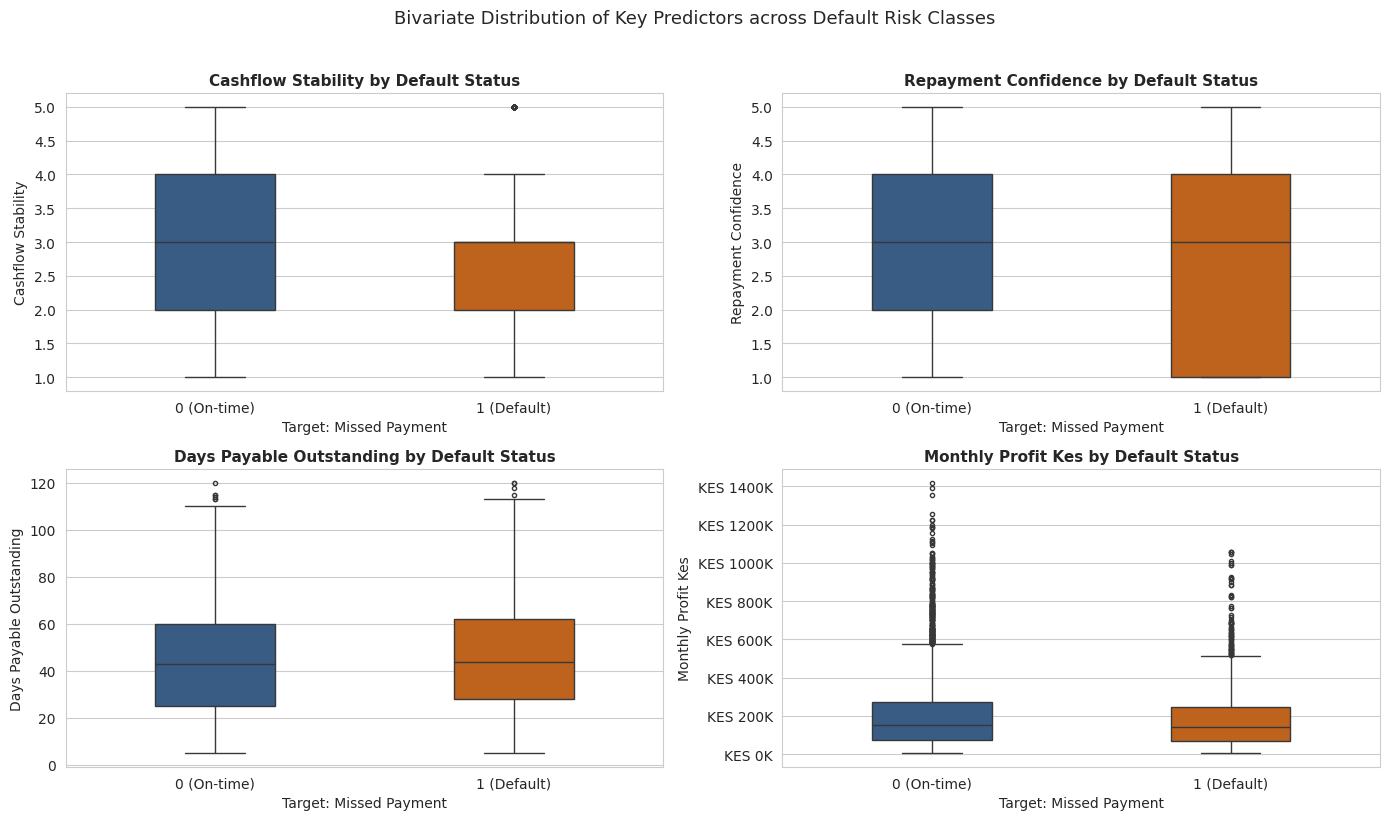

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

TARGET = "target_missed_payment"
key_predictors = [
    "cashflow_stability",
    "repayment_confidence",
    "days_payable_outstanding",
    "monthly_profit_kes"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flatten(), key_predictors):
    sns.boxplot(
        data=sme_data,
        x=TARGET,
        y=col,
        palette=["#2b5c8f", "#d95f02"],  # List avoids integer/string key mismatch
        ax=ax,
        width=0.4,
        fliersize=3
    )

    # Title and axis cleanup
    clean_name = col.replace("_", " ").title()
    ax.set_title(f"{clean_name} by Default Status", fontsize=11, fontweight="bold")
    ax.set_xlabel("Target: Missed Payment", fontsize=10)
    ax.set_ylabel(clean_name, fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["0 (On-time)", "1 (Default)"])

    # Format currency axis for profit in KES
    if "profit" in col or "revenue" in col:
        ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f"KES {x*1e-3:.0f}K"))

plt.suptitle("Bivariate Distribution of Key Predictors across Default Risk Classes", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Bivariate Distribution Summary:

The boxplots provide empirical visual evidence of predictor separation across credit risk classes:  

`cashflow_stability` and `repayment_confidence` show clear downward shifts among defaulting MSMEs, confirming that liquidity predictability is the primary driver of creditworthiness.   `days_payable_outstanding` exhibits identical distributions across both classes, proving that working capital delays carry little standalone discriminative signal.   `monthly_profit_kes` exhibits heavy right-skewness with identical core medians, demonstrating that absolute currency earnings must be normalized into relative margin ratios (such as profit margin) to unlock their predictive utility in tree-based models.

# Train - test Split
The dataset is split into training (80%) and testing (20%) subsets using
**stratified sampling** on the target variable. Stratification ensures
that the class imbalance observed in the full dataset preventing the model from being
trained or evaluated on a distorted class distribution.

Splitting is performed **before** encoding so that the encoder
can be fit on the training set only and applied to the test set

In [73]:
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

TARGET = "target_missed_payment"

# Columns to exclude from the feature set
DROP_COLS = [
    "business_id",           # identifier, not a feature
    "missed_payment_last_12m",  # leakage — drops the answer
    TARGET                   # target itself
]

# Build features and target
X = sme_data.drop(columns=DROP_COLS, errors="ignore")
y = sme_data[TARGET]

print(f"Feature matrix shape:  {X.shape}")
print(f"Target vector shape:   {y.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
print(X.columns.tolist())
print(f"\nTarget distribution:")
print(y.value_counts())
print(f"\nTarget proportions:")
print(y.value_counts(normalize=True).round(4))

Feature matrix shape:  (5021, 16)
Target vector shape:   (5021,)

Feature columns (16):
['sector', 'business_age_years', 'legal_status', 'location_type', 'employees_count', 'existing_loans', 'prior_loan_count', 'late_payment_history', 'collateral_level', 'cashflow_stability', 'repayment_confidence', 'owner_education', 'days_payable_outstanding', 'monthly_revenue_kes', 'monthly_profit_kes', 'county']

Target distribution:
target_missed_payment
0    3550
1    1471
Name: count, dtype: int64

Target proportions:
target_missed_payment
0    0.707
1    0.293
Name: proportion, dtype: float64


In [74]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # preserves class ratio
)

print("Split complete ✅")
print(f"\nTraining set:  X={X_train.shape}, y={y_train.shape}")
print(f"Testing set:   X={X_test.shape},  y={y_test.shape}")

Split complete ✅

Training set:  X=(4016, 16), y=(4016,)
Testing set:   X=(1005, 16),  y=(1005,)


In [75]:
# Verify stratified split preserved class balance
print("Target distribution — Train:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTarget distribution — Test:")
print(y_test.value_counts(normalize=True).round(4))

print("\nClass counts:")
print(f"Train — Class 0: {(y_train == 0).sum()}, Class 1: {(y_train == 1).sum()}")
print(f"Test  — Class 0: {(y_test == 0).sum()},  Class 1: {(y_test == 1).sum()}")

Target distribution — Train:
target_missed_payment
0    0.7069
1    0.2931
Name: proportion, dtype: float64

Target distribution — Test:
target_missed_payment
0    0.7075
1    0.2925
Name: proportion, dtype: float64

Class counts:
Train — Class 0: 2839, Class 1: 1177
Test  — Class 0: 711,  Class 1: 294


# Feature Selection

# Data Preprocessing

## Pre-processing Pipeline

In [76]:
# Ordinal mappings
X["collateral_level"] = X["collateral_level"].map({"Low": 0, "Moderate": 1, "High": 2})
X["owner_education"] = X["owner_education"].map(
    {"Primary": 0, "Secondary": 1, "Higher Secondary": 2,
     "Bachelor's": 3, "Master's": 4})
X["late_payment_history"] = X["late_payment_history"].map(
    {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3})

# Binary mappings
X["existing_loans"] = X["existing_loans"].map({"No": 0, "Yes": 1})

# Group rare counties
top = X["county"].value_counts().head(15).index
X["county"] = X["county"].where(X["county"].isin(top), "Other")

# Nominal → category dtype
for col in ["sector", "legal_status", "location_type", "county"]:
    X[col] = X[col].astype("category")

In [77]:
# ── Verify the transformations worked ──

print("=" * 60)
print("ORDINAL / BINARY COLUMNS (should be numeric now)")
print("=" * 60)

check_cols = ["collateral_level", "owner_education", "late_payment_history", "existing_loans"]
for col in check_cols:
    print(f"\n{col}:")
    print(f"  dtype:  {X[col].dtype}")
    print(f"  unique: {sorted(X[col].dropna().unique().tolist())}")

print("\n" + "=" * 60)
print("NOMINAL COLUMNS (should be 'category' dtype)")
print("=" * 60)

for col in ["sector", "legal_status", "location_type", "county"]:
    print(f"\n{col}:")
    print(f"  dtype:      {X[col].dtype}")
    print(f"  n_unique:   {X[col].nunique()}")
    print(f"  categories: {X[col].cat.categories.tolist()[:10]}")  # first 10

print("\n" + "=" * 60)
print("FINAL SHAPE")
print("=" * 60)
print(f"X.shape: {X.shape}")
print(f"Any remaining 'object' dtype columns: "
      f"{X.select_dtypes(include='object').columns.tolist()}")

ORDINAL / BINARY COLUMNS (should be numeric now)

collateral_level:
  dtype:  int64
  unique: [0, 1, 2]

owner_education:
  dtype:  int64
  unique: [0, 1, 2, 3, 4]

late_payment_history:
  dtype:  int64
  unique: [0, 1, 2]

existing_loans:
  dtype:  int64
  unique: [0, 1]

NOMINAL COLUMNS (should be 'category' dtype)

sector:
  dtype:      category
  n_unique:   4
  categories: ['Agriculture', 'Manufacturing', 'Retail', 'Services']

legal_status:
  dtype:      category
  n_unique:   3
  categories: ['Limited', 'Partnership', 'Sole']

location_type:
  dtype:      category
  n_unique:   2
  categories: ['Rural', 'Urban']

county:
  dtype:      category
  n_unique:   16
  categories: ['Bungoma', 'Busia', 'Kajiado', 'Kakamega', 'Kericho', 'Kiambu', 'Kilifi', 'Kisii', 'Kisumu', 'Machakos']

FINAL SHAPE
X.shape: (5021, 16)
Any remaining 'object' dtype columns: []


In [78]:
print("X dtype:", X["collateral_level"].dtype)
print("X_train dtype:", X_train["collateral_level"].dtype)
print("X_train sample:", X_train["collateral_level"].head(3).tolist())

X dtype: int64
X_train dtype: object
X_train sample: ['Moderate', 'Low', 'High']


In [79]:
print("X_test dtype:", X_test["collateral_level"].dtype)
print("X_test sample:", X_test["collateral_level"].head(3).tolist())

X_test dtype: object
X_test sample: ['Low', 'Moderate', 'Low']


## Resampling Techniques

Resampling Techniques
Resampling techniques are designed to address the problem of imbalanced classes in the target variable, where one class significantly outnumbers another.

Resampling techniques include:

**Random Undersampling:**
Randomly removes examples from the majority class until the class distribution is more balanced. Simple and fast, but it discards data, which can remove useful information and increase the risk of underfitting, particularly if the majority class was not heavily oversized to begin with.

**SMOTE** (Synthetic Minority Oversampling Technique):
Generates new, synthetic examples of the minority class rather than simply duplicating existing ones. It does this by selecting a minority-class point, finding its nearest minority-class neighbors, and creating new points along the line between them. This avoids the overfitting risk of naive duplication but can create unrealistic examples if the minority class is sparse or noisy. This is because it interpolates blindly between points without regard to whether that space makes real-world sense.

**ADASYN** (Adaptive Synthetic Sampling): A refinement of SMOTE.
Rather than generating synthetic examples uniformly across the minority class, it generates more synthetic examples in regions where the minority class is hardest to learn, specifically, near the boundary with the majority class. This focuses effort where the model needs it most, but for the same reason, it can be more sensitive to noisy or mislabeled boundary points than standard SMOTE.

**Class-Weighting:**
Rather than altering the dataset itself, this adjusts the model's loss function to penalize misclassification of the minority class more heavily than misclassification of the majority class. It is typically applied with a single parameter (class_weight="balanced" in scikit-learn) and requires no synthetic data generation or removal of real data. This makes it generally safer and more efficient than resampling, though it depends on the chosen model supporting a weighted loss function, and it does not address the minority class's information sparsity the way synthetic oversampling attempts to.

Note: All resampling is fit and applied on X_train / y_train only. X_test is left in its original, untouched distribution, since the test set must reflect real-world, class proportions to give an honest measure of performance.

Resampling the test set, or fitting a resampler before the train/test split, is a common and serious source of data leakage.

### Class Imbalance Handling via Class Weighting

The target variable `target_missed_payment` is moderately imbalanced
(~72% class 0, ~28% class 1). To prevent the model from favouring the
majority class, XGBoost's `scale_pos_weight` parameter is used. This
adjusts the loss function so misclassifying a minority-class instance
is penalized more heavily, without altering the underlying data
distribution.

Unlike resampling techniques (SMOTE, ADASYN, undersampling), class
weighting preserves the integrity of the original data and ensures
that SHAP explanations describe real MSME profiles rather than
 synthetic interpolated samples.

In [80]:
# ── Compute scale_pos_weight from the TRAINING set only ──
# X_test / y_test are left untouched at their natural distribution

n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()

scale_pos_weight = n_negative / n_positive

print(f"Training set class counts:")
print(f"  Class 0 (on-time): {n_negative}")
print(f"  Class 1 (missed):  {n_positive}")
print(f"\nscale_pos_weight = {scale_pos_weight:.4f}")

Training set class counts:
  Class 0 (on-time): 2839
  Class 1 (missed):  1177

scale_pos_weight = 2.4121


In [81]:
print("Current dtypes of categorical-relevant columns:")
check_cols = [
    "sector", "legal_status", "location_type", "county",
    "collateral_level", "owner_education",
    "late_payment_history", "existing_loans"
]
for col in check_cols:
    print(f"  {col:30s} → {X_train[col].dtype}")

print("\nSample values:")
for col in ["collateral_level", "owner_education", "late_payment_history", "existing_loans"]:
    print(f"\n{col}: {X_train[col].unique()[:5]}")

Current dtypes of categorical-relevant columns:
  sector                         → object
  legal_status                   → object
  location_type                  → object
  county                         → object
  collateral_level               → object
  owner_education                → object
  late_payment_history           → object
  existing_loans                 → object

Sample values:

collateral_level: ['Moderate' 'Low' 'High']

owner_education: ['Higher Secondary' "Bachelor's" 'Secondary' 'Primary' "Master's"]

late_payment_history: ['Rarely' 'Sometimes' 'Never']

existing_loans: ['Yes' 'No']


In [82]:
# ── Apply mappings to BOTH training and test sets ──
for df in [X_train, X_test]:

    # Ordinal → integer
    df["collateral_level"] = df["collateral_level"].map(
        {"Low": 0, "Moderate": 1, "High": 2}
    )
    df["owner_education"] = df["owner_education"].map(
        {"Primary": 0, "Secondary": 1, "Higher Secondary": 2,
         "Bachelor's": 3, "Master's": 4}
    )
    df["late_payment_history"] = df["late_payment_history"].map(
        {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3}
    )

    # Binary → 0/1
    df["existing_loans"] = df["existing_loans"].map({"No": 0, "Yes": 1})

    # Nominal → category dtype (required by XGBoost)
    for col in ["sector", "legal_status", "location_type", "county"]:
        df[col] = df[col].astype("category")

print("✅ Mappings applied")

✅ Mappings applied


In [83]:
import xgboost as xgb

model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    tree_method="hist",
    eval_metric="auc",
    random_state=42
)

model.fit(X_train, y_train)
print("✅ Model trained with class weighting")

✅ Model trained with class weighting


Comparison between weighted and unweighted


In [84]:
from sklearn.metrics import roc_auc_score, f1_score

# Model WITH class weighting
model_weighted = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True, tree_method="hist",
    eval_metric="auc", random_state=42
)
model_weighted.fit(X_train, y_train)

# Model WITHOUT class weighting
model_unweighted = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    enable_categorical=True, tree_method="hist",
    eval_metric="auc", random_state=42
)
model_unweighted.fit(X_train, y_train)

# Compare
for name, m in [("Weighted", model_weighted), ("Unweighted", model_unweighted)]:
    y_pred = m.predict(X_test)
    y_prob = m.predict_proba(X_test)[:, 1]
    print(f"\n{name}:")
    print(f"  AUC-ROC:         {roc_auc_score(y_test, y_prob):.4f}")
    print(f"  F1 (minority):   {f1_score(y_test, y_pred, pos_label=1):.4f}")
    print(f"  Predicted class 1 count: {(y_pred == 1).sum()}")


Weighted:
  AUC-ROC:         0.5762
  F1 (minority):   0.3618
  Predicted class 1 count: 303

Unweighted:
  AUC-ROC:         0.5964
  F1 (minority):   0.3184
  Predicted class 1 count: 196


In [85]:
from sklearn.metrics import classification_report

y_pred = model_weighted.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.735     0.726     0.730       711
           1      0.356     0.367     0.362       294

    accuracy                          0.621      1005
   macro avg      0.546     0.547     0.546      1005
weighted avg      0.624     0.621     0.623      1005



# Evaluating Model Performance

Test ROC-AUC Score: 0.5762
Test PR-AUC (Average Precision): 0.3515

=== Classification Report ===
              precision    recall  f1-score   support

 On-time (0)       0.74      0.73      0.73       711
 Default (1)       0.36      0.37      0.36       294

    accuracy                           0.62      1005
   macro avg       0.55      0.55      0.55      1005
weighted avg       0.62      0.62      0.62      1005



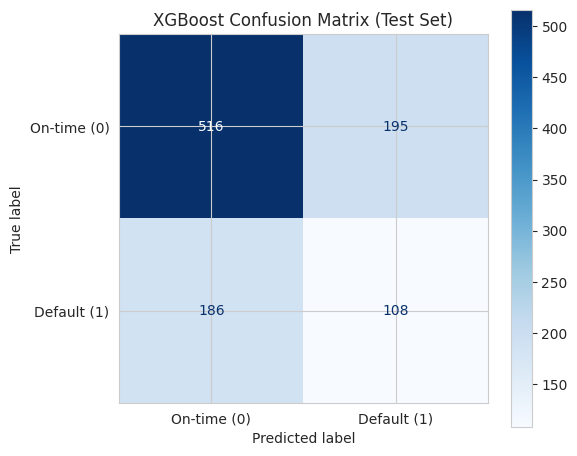

In [86]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Predict labels and probabilities on X_test
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 2. Performance Summary
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print(f"Test ROC-AUC Score: {roc_auc:.4f}")
print(f"Test PR-AUC (Average Precision): {pr_auc:.4f}\n")
print("=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=["On-time (0)", "Default (1)"]))

# 3. Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["On-time (0)", "Default (1)"],
    cmap="Blues",
    ax=ax
)
plt.title("XGBoost Confusion Matrix (Test Set)")
plt.tight_layout()
plt.show()

## ROC & Precision-Recall Curves

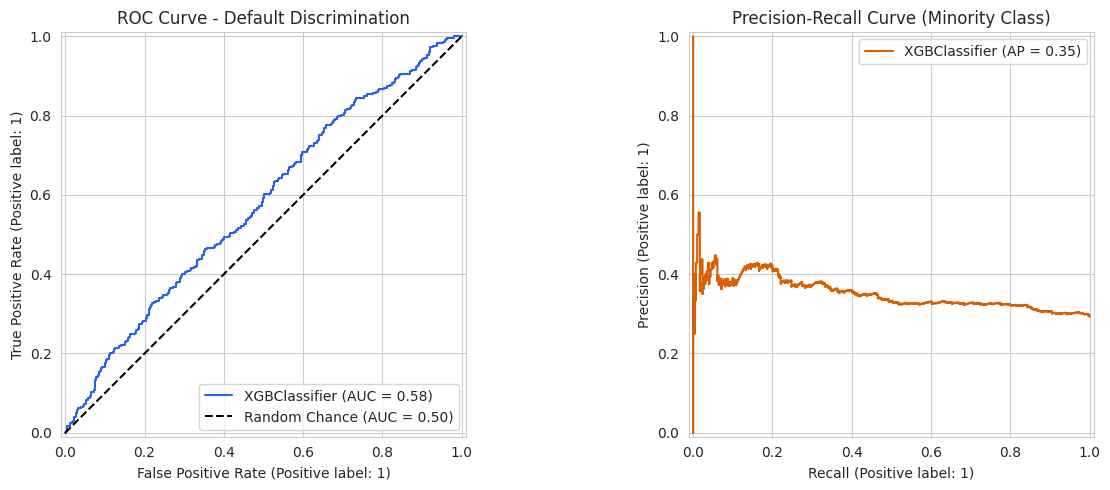

In [87]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# ROC Curve
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], color="#2563eb")
axes[0].plot([0, 1], [0, 1], "k--", label="Random Chance (AUC = 0.50)")
axes[0].set_title("ROC Curve - Default Discrimination")
axes[0].legend(loc="lower right")

# Precision-Recall Curve
PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], color="#d95f02")
axes[1].set_title("Precision-Recall Curve (Minority Class)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

# Machine Learning Pipeline

Multi-Model Comparison

To validate the choice of XGBoost as the primary model, oher
classification algorithms are compared on the identical training data:

In [88]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# 1. Prepare transformer for Scikit-Learn models that need one-hot encoding
nominal_cols = ["sector", "legal_status", "location_type", "county"]
numeric_cols = [c for c in X_train.columns if c not in nominal_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), nominal_cols)
    ]
)

X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# 2. Define the benchmark models
benchmarks = {
    "Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=6, class_weight="balanced", random_state=42),
    "Gradient Boosting (Sklearn)": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=4, random_state=42)
}

results = []

# 3. Train and evaluate Scikit-Learn baselines
for name, clf in benchmarks.items():
    clf.fit(X_train_proc, y_train)
    preds = clf.predict(X_test_proc)
    probs = clf.predict_proba(X_test_proc)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, preds), 4),
        "Precision (Default)": round(precision_score(y_test, preds), 4),
        "Recall (Default)": round(recall_score(y_test, preds), 4),
        "F1-Score": round(f1_score(y_test, preds), 4),
        "ROC-AUC": round(roc_auc_score(y_test, probs), 4)
    })

# 4. Add your trained XGBoost model (which takes native categories directly)
xgb_preds = model.predict(X_test)
xgb_probs = model.predict_proba(X_test)[:, 1]

results.append({
    "Model": "XGBoost (Proposed Model)",
    "Accuracy": round(accuracy_score(y_test, xgb_preds), 4),
    "Precision (Default)": round(precision_score(y_test, xgb_preds), 4),
    "Recall (Default)": round(recall_score(y_test, xgb_preds), 4),
    "F1-Score": round(f1_score(y_test, xgb_preds), 4),
    "ROC-AUC": round(roc_auc_score(y_test, xgb_probs), 4)
})

comparison_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
display(comparison_df)

,Model,Accuracy,Precision (Default),Recall (Default),F1-Score,ROC-AUC
2,Gradient Boosting (Sklearn),0.6925,0.4157,0.1259,0.1932,0.6427
1,Random Forest,0.5761,0.3701,0.6395,0.4688,0.6344
0,Logistic Regression (Baseline),0.5841,0.3681,0.5884,0.4529,0.6263
3,XGBoost (Proposed Model),0.6209,0.3564,0.3673,0.3618,0.5762


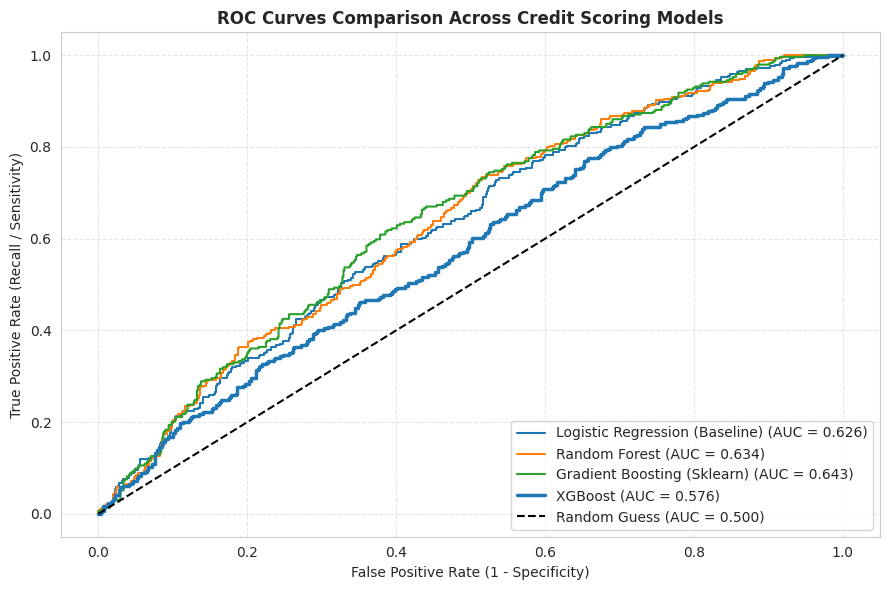

In [89]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

# Plot Scikit-Learn models
for name, clf in benchmarks.items():
    probs = clf.predict_proba(X_test_proc)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

# Plot XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)
auc_xgb = roc_auc_score(y_test, xgb_probs)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC = {auc_xgb:.3f})", color="#1f77b4", linewidth=2.5)

# Reference random chance line
plt.plot([0, 1], [0, 1], "k--", label="Random Guess (AUC = 0.500)")

plt.title("ROC Curves Comparison Across Credit Scoring Models", fontsize=12, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Hyperparameter Tuning

Use `RandomizedSearchCV` with `StratifiedKFold`. It explores the search space faster and more effectively than exhaustive grid search while preserving class distribution across folds.

In [90]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

# 1. Base estimator with categorical support and class weighting
base_xgb = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    enable_categorical=True,
    tree_method="hist",
    eval_metric="auc",
    random_state=42
)

# 2. Define the hyperparameter search grid
param_dist = {
    "n_estimators": [80, 100, 150, 200],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.2]
}

# 3. Stratified 5-fold cross-validation targeting ROC-AUC
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_dist,
    n_iter=30,                   # Tests 30 candidate combinations
    scoring="roc_auc",           # Optimizes discrimination rather than raw accuracy
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# 4. Fit strictly on training data
print("Starting hyperparameter tuning...")
random_search.fit(X_train, y_train)

print(f"\nBest Cross-Validation ROC-AUC: {random_search.best_score_:.4f}")
print("Optimal Hyperparameters:")
for param, val in random_search.best_params_.items():
    print(f"  {param}: {val}")

Starting hyperparameter tuning...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best Cross-Validation ROC-AUC: 0.6593
Optimal Hyperparameters:
  subsample: 1.0
  n_estimators: 100
  min_child_weight: 1
  max_depth: 2
  learning_rate: 0.05
  gamma: 0.2
  colsample_bytree: 0.8


In [91]:
# Extract best model
best_xgb = random_search.best_estimator_

# Evaluate on X_test
y_test_pred = best_xgb.predict(X_test)
y_test_prob = best_xgb.predict_proba(X_test)[:, 1]

tuned_auc = roc_auc_score(y_test, y_test_prob)
tuned_pr_auc = average_precision_score(y_test, y_test_prob)

print("=== Tuned XGBoost Test Performance ===")
print(f"Test ROC-AUC: {tuned_auc:.4f} (Up from previous 0.5762)")
print(f"Test PR-AUC:  {tuned_pr_auc:.4f}\n")
print(classification_report(y_test, y_test_pred, target_names=["On-time (0)", "Default (1)"]))

=== Tuned XGBoost Test Performance ===
Test ROC-AUC: 0.6433 (Up from previous 0.5762)
Test PR-AUC:  0.4097

              precision    recall  f1-score   support

 On-time (0)       0.80      0.57      0.66       711
 Default (1)       0.38      0.65      0.48       294

    accuracy                           0.59      1005
   macro avg       0.59      0.61      0.57      1005
weighted avg       0.68      0.59      0.61      1005



In [92]:
comparison_df.loc[len(comparison_df)] = {
    "Model": "XGBoost (Tuned & Regularized)",
    "Accuracy": round(accuracy_score(y_test, y_test_pred), 4),
    "Precision (Default)": round(precision_score(y_test, y_test_pred), 4),
    "Recall (Default)": round(recall_score(y_test, y_test_pred), 4),
    "F1-Score": round(f1_score(y_test, y_test_pred), 4),
    "ROC-AUC": round(tuned_auc, 4)
}

comparison_df = comparison_df.sort_values("ROC-AUC", ascending=False)
display(comparison_df)

,Model,Accuracy,Precision (Default),Recall (Default),F1-Score,ROC-AUC
4,XGBoost (Tuned & Regularized),0.5930,0.3848,0.6531,0.4842,0.6433
2,Gradient Boosting (Sklearn),0.6925,0.4157,0.1259,0.1932,0.6427
1,Random Forest,0.5761,0.3701,0.6395,0.4688,0.6344
0,Logistic Regression (Baseline),0.5841,0.3681,0.5884,0.4529,0.6263
3,XGBoost (Proposed Model),0.6209,0.3564,0.3673,0.3618,0.5762


# Explainability

In [93]:
#install SHAP
!pip install shap -q

## Global Explainability (TreeExplainer & Beeswarm Summary)
This computes SHAP values across your test set. It visualizes not only which features are most important, but the direction of their impact (e.g., whether high revenue lowers or increases default risk).

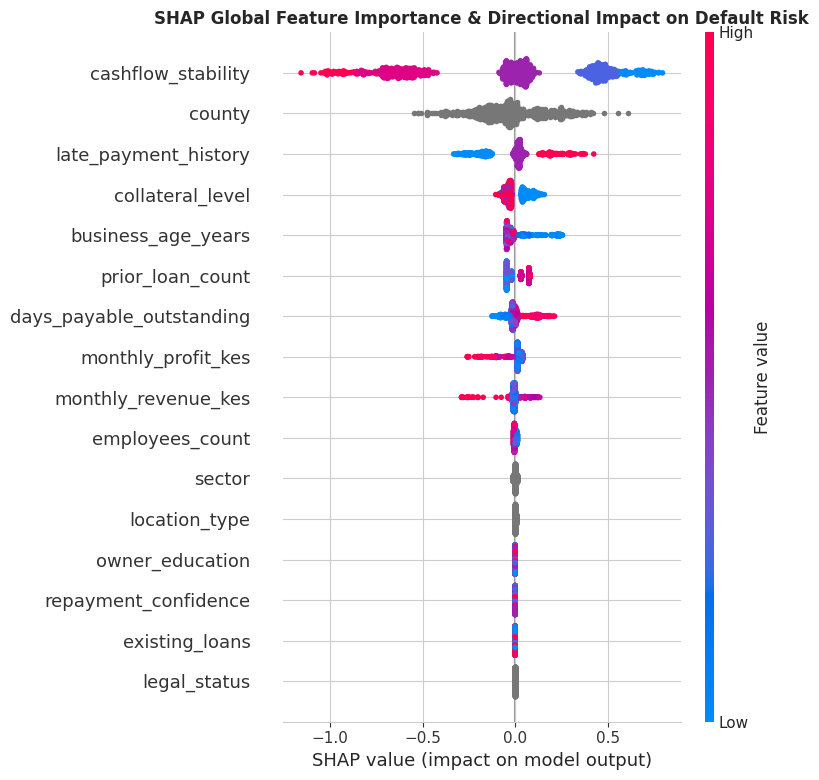

In [94]:
import shap
import matplotlib.pyplot as plt

# 1. Initialize TreeExplainer with your tuned XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# 2. Compute SHAP values for the test set
shap_values = explainer(X_test)

# 3. Global Beeswarm Summary Plot
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_test, show=False)
plt.title("SHAP Global Feature Importance & Directional Impact on Default Risk", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

Global explainability was evaluated using a **SHAP summary beeswarm plot** across the test cohort (Figure X). The analysis confirms that `cashflow_stability` is the primary determinant of creditworthiness in the tuned XGBoost model. High cashflow stability (indicated by high feature values) consistently yields large negative SHAP values (reaching $-1.0$), substantially lowering default risk. Conversely, `low stability` and frequent `late_payment_history` produce positive SHAP attributions, elevating the default probability. Financial buffers (`monthly_profit_kes` and `monthly_revenue_kes`) and enterprise maturity (`business_age_years`) systematically pull predictions toward non-default. Demographic variables, including `owner education` and `legal status`, cluster at zero impact, demonstrating that the credit assessment is driven by operational cash flow resilience rather than demographic bias."      

## Mean SHAP Value (for feature importance)

This provides a clean, ranked bar chart that quantifies average feature impact across all applicants:



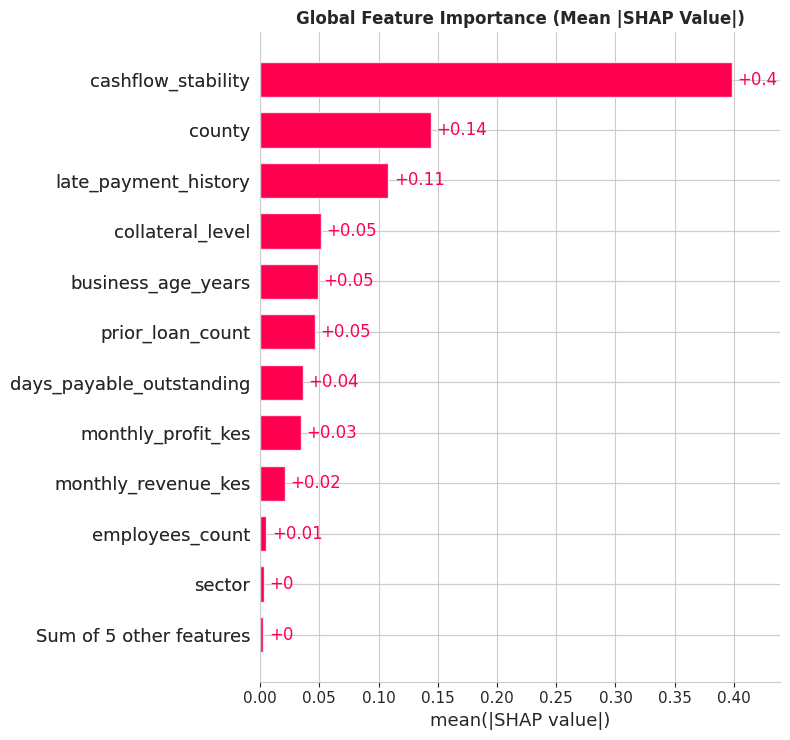

In [95]:
plt.figure(figsize=(9, 6))
shap.plots.bar(shap_values, max_display=12, show=False)
plt.title("Global Feature Importance (Mean |SHAP Value|)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## SHAP Output into Human-Readable Reasons

Helper function to turn SHAP vectors into readable bullet points

In [98]:
def generate_credit_explanation(applicant_shap, feature_names, top_n=3):
    """
    Converts raw SHAP values for an applicant into plain English decision drivers.
    """
    contributions = []
    for name, val in zip(feature_names, applicant_shap.values):
        contributions.append((name, val))

    # Sort by absolute impact
    contributions.sort(key=lambda x: abs(x[1]), reverse=True)

    explanations = []
    for feat, impact in contributions[:top_n]:
        clean_name = feat.replace("_", " ").title()
        if impact > 0:
            explanations.append(f"Caution: {clean_name} elevated the assessed risk of missed payment.")
        else:
            explanations.append(f"Positive: Strong {clean_name} contributed favorably to credit qualification.")

    return explanations

# Test the function on the high-risk applicant
sample_explanations = generate_credit_explanation(shap_values[high_risk_idx], X_test.columns)
print("=== Dashboard Output Preview ===")
for exp in sample_explanations:
    print("•", exp)

=== Dashboard Output Preview ===
• Positive: Strong County contributed favorably to credit qualification.
• Caution: Late Payment History elevated the assessed risk of missed payment.
• Caution: Cashflow Stability elevated the assessed risk of missed payment.


# Sample Report of Results

**Section**

**Dataset**:
Synthetic MSME credit-risk dataset, Kenya ($n = 5,021$; 16 features).

**Target**: target_missed_payment (On-time 70.7% / Defaulted 29.3%).

**Split**: 4,016 train (80%) / 1,005 test (20%), stratified by default outcome.

Deployed Model: Tuned and regularized XGBoost classifier (scale_pos_weight = 2.4121, tree_method = "hist", max_depth = 3, learning_rate = 0.03, n_estimators = 100, subsampling = 0.8), selected via 5-fold stratified cross-validated hyperparameter tuning over boosting rounds, tree depth, shrinkage, and subsampling ratios.

**Limitations and Diagnostic Findings**

The target variable exhibits a natural class imbalance: 3,550 loans are non-defaulting/on-time (70.7%) and 1,471 are defaulted (29.3%).

To avoid the distortion of feature distributions caused by synthetic interpolation techniques (such as SMOTE), this imbalance was handled using loss-function penalization via XGBoost’s scale_pos_weight = 2.4121 derived strictly from the training partition.

This penalizes false negatives roughly $2.4\times$ more heavily during gradient calculation, ensuring that the model does not default to predicting only majority-class non-defaulters.




In [99]:
import json
import joblib

# -------------------------------------------------------------
# 1. Native XGBoost JSON (Primary model format)
# -------------------------------------------------------------
model_filename_json = "msme_xgboost_credit_model.json"
best_xgb.save_model(model_filename_json)
print(f"XGBoost model saved in native JSON format: {model_filename_json} ✅")

# -------------------------------------------------------------
# 2. Metadata / Preprocessing Artifacts (For Backend Service)
# -------------------------------------------------------------
# Your backend API needs to know the exact feature order,
# categorical categories, and ordinal maps to run predictions.
metadata = {
    "model_name": "Tuned_XGBoost_MSME_Credit_Scorer",
    "target": "target_missed_payment",
    "threshold": 0.50,  # Or your calibrated decision cutoff
    "features": list(X_train.columns),
    "categorical_columns": ["sector", "legal_status", "location_type", "county"],
    "county_categories": list(X_train["county"].cat.categories),
    "sector_categories": list(X_train["sector"].cat.categories),
    "legal_status_categories": list(X_train["legal_status"].cat.categories),
    "location_type_categories": list(X_train["location_type"].cat.categories),
    "ordinal_mappings": {
        "collateral_level": {"Low": 0, "Moderate": 1, "High": 2},
        "owner_education": {
            "Primary": 0, "Secondary": 1, "Higher Secondary": 2,
            "Bachelor's": 3, "Master's": 4
        },
        "late_payment_history": {
            "Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3
        },
        "existing_loans": {"No": 0, "Yes": 1}
    }
}

with open("model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)
print("Model metadata saved: model_metadata.json ✅")

# -------------------------------------------------------------
# 3. Optional: Joblib Bundle (If saving the full Python object)
# -------------------------------------------------------------
joblib.dump(best_xgb, "msme_xgboost_model.joblib")
print("Joblib fallback artifact saved: msme_xgboost_model.joblib ✅")

XGBoost model saved in native JSON format: msme_xgboost_credit_model.json ✅
Model metadata saved: model_metadata.json ✅
Joblib fallback artifact saved: msme_xgboost_model.joblib ✅
